In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve

# Notebook is in .../Group Sprint 1/notebooks
BASE = Path("..").resolve()
CLEAN_PATH = BASE / "data" / "cleaned" / "shots_cleaned.csv"
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv(CLEAN_PATH)
print(df.shape)

# Placeholder split: must match the group's agreed split and the null-model notebook
TRAIN_SEASONS = ["2021/22", "2022/23", "2023/24"]
VAL_SEASONS   = ["2024/25"]
TEST_SEASONS  = ["2025/26"]   # held out: do not use until decisions are frozen
# 2026/27 is excluded (only 60 matches so far)

train = df[df["season"].isin(TRAIN_SEASONS)].copy()
val   = df[df["season"].isin(VAL_SEASONS)].copy()
print(f"train: {len(train)}  validation: {len(val)}")

y_train = train["result"].to_numpy()
y_val   = val["result"].to_numpy()

(50798, 38)
train: 29813  validation: 9844


In [3]:
# x runs 0-120 and y 0-80 in the data. Convert to a 105 x 68 m pitch;
# the goal centre is at (105, 34).
PITCH_L, PITCH_W, GOAL_W = 105, 68, 7.32

def add_spatial_features(d):
    d = d.copy()
    x_m = d["x"] * PITCH_L / 120
    y_m = d["y"] * PITCH_W / 80
    d["dist_goal_line"] = PITCH_L - x_m                  # from x
    d["lateral_offset"] = (y_m - PITCH_W / 2).abs()      # from y
    d["distance"] = np.sqrt(d["dist_goal_line"] ** 2 + d["lateral_offset"] ** 2)  # comparison model only
    return d

train = add_spatial_features(train)
val = add_spatial_features(val)

CORE_FEATURES = ["dist_goal_line", "lateral_offset", "angle_to_goal"]
DIST_ANGLE_FEATURES = ["distance", "angle_to_goal"]   # comparison model only

In [4]:
display(train[CORE_FEATURES].describe().round(3))
display(train[CORE_FEATURES].corr().round(3))

,dist_goal_line,lateral_offset,angle_to_goal
count,29813.000,29813.000,29813.000
mean,14.961,6.734,0.457
std,7.745,4.800,0.279
min,0.315,0.000,0.002
25%,9.030,2.652,0.270
50%,13.650,5.916,0.363
75%,20.790,10.472,0.565
max,74.025,33.660,2.847


,dist_goal_line,lateral_offset,angle_to_goal
dist_goal_line,1.000,0.130,-0.616
lateral_offset,0.130,1.000,-0.563
angle_to_goal,-0.616,-0.563,1.000


In [5]:
X_train = sm.add_constant(train[CORE_FEATURES])
X_val = sm.add_constant(val[CORE_FEATURES], has_constant="add")

# Variance inflation factors (values below about 5 are comfortable)
vif = pd.Series(
    [variance_inflation_factor(X_train.values, i) for i in range(1, X_train.shape[1])],
    index=CORE_FEATURES,
).round(2)
display(vif)

core_fit = sm.Logit(y_train, X_train).fit()
print(core_fit.summary())

conf = core_fit.conf_int()
or_table = pd.DataFrame({
    "odds_ratio": np.exp(core_fit.params),
    "ci_low": np.exp(conf[0]),
    "ci_high": np.exp(conf[1]),
}).round(4)
display(or_table)

dist_goal_line    1.81
lateral_offset    1.64
angle_to_goal     2.60
dtype: float64

Optimization terminated successfully.
         Current function value: 0.307563
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                29813
Model:                          Logit   Df Residuals:                    29809
Method:                           MLE   Df Model:                            3
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.1109
Time:                        14:32:49   Log-Likelihood:                -9169.4
converged:                       True   LL-Null:                       -10313.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -1.5775      0.121    -13.050      0.000      -1.814      -1.341
dist_goal_line   

,odds_ratio,ci_low,ci_high
const,0.2065,0.1629,0.2617
dist_goal_line,0.9503,0.9423,0.9584
lateral_offset,0.9161,0.9047,0.9276
angle_to_goal,3.2504,2.7002,3.9129


In [6]:
p_core_train = np.asarray(core_fit.predict(X_train))
p_core_val = np.asarray(core_fit.predict(X_val))

# Cross-check with scikit-learn (very large C = effectively unpenalised)
skl = LogisticRegression(C=1e10, max_iter=5000).fit(train[CORE_FEATURES], y_train)
diff = np.abs(skl.predict_proba(val[CORE_FEATURES])[:, 1] - p_core_val).max()
print(f"Max difference between statsmodels and sklearn: {diff:.4f}")
assert diff < 0.01

Max difference between statsmodels and sklearn: 0.0000


In [7]:
# Comparison model: distance + angle only
Xd_train = sm.add_constant(train[DIST_ANGLE_FEATURES])
Xd_val = sm.add_constant(val[DIST_ANGLE_FEATURES], has_constant="add")
da_fit = sm.Logit(y_train, Xd_train).fit(disp=0)
p_da_train = np.asarray(da_fit.predict(Xd_train))
p_da_val = np.asarray(da_fit.predict(Xd_val))

def evaluate(y_true, p_pred):
    p = np.clip(p_pred, 1e-15, 1 - 1e-15)
    return {
        "log_loss": log_loss(y_true, p),
        "brier": brier_score_loss(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "mean_pred": p.mean(),
        "observed_rate": y_true.mean(),
    }

p0 = y_train.mean()   # null model: training goal rate for every shot

results = pd.DataFrame({
    ("train", "null"): evaluate(y_train, np.full(len(y_train), p0)),
    ("train", "distance_angle"): evaluate(y_train, p_da_train),
    ("train", "core_spatial"): evaluate(y_train, p_core_train),
    ("train", "understat_xg"): evaluate(y_train, train["xg"].to_numpy()),
    ("validation", "null"): evaluate(y_val, np.full(len(y_val), p0)),
    ("validation", "distance_angle"): evaluate(y_val, p_da_val),
    ("validation", "core_spatial"): evaluate(y_val, p_core_val),
    ("validation", "understat_xg"): evaluate(y_val, val["xg"].to_numpy()),
}).T.round(4)
results.index.names = ["split", "model"]
display(results)

# AIC (lower is better) compares the two logistic models on the training data
print(pd.Series({"distance_angle": da_fit.aic, "core_spatial": core_fit.aic}).round(1))

log_loss   brier  roc_auc  mean_pred  observed_rate
split      model                                                              
train      null              0.3459  0.0977   0.5000     0.1097         0.1097
           distance_angle    0.3096  0.0890   0.7313     0.1097         0.1097
           core_spatial      0.3076  0.0885   0.7379     0.1097         0.1097
           understat_xg      0.2658  0.0752   0.8116     0.1191         0.1097
validation null              0.3461  0.0978   0.5000     0.1097         0.1098
           distance_angle    0.3137  0.0898   0.7166     0.1116         0.1098
           core_spatial      0.3132  0.0895   0.7182     0.1115         0.1098
           understat_xg      0.2715  0.0774   0.8058     0.1256         0.1098

distance_angle    18468.4
core_spatial      18346.8
dtype: float64


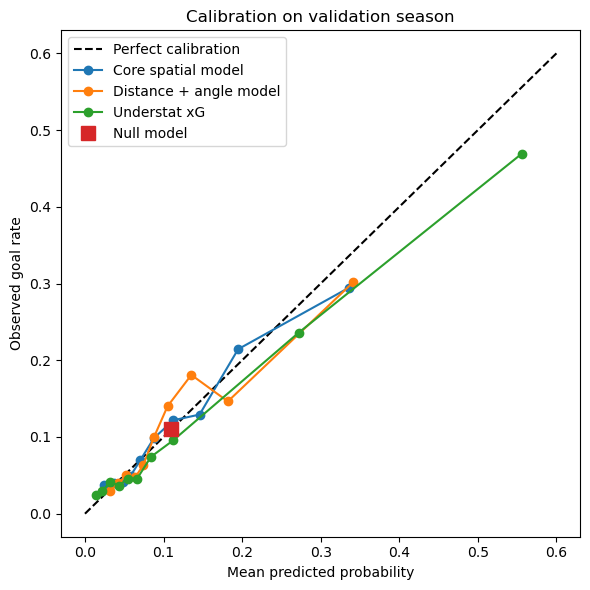

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.6], [0, 0.6], "k--", label="Perfect calibration")
for p, label in [(p_core_val, "Core spatial model"),
                 (p_da_val, "Distance + angle model"),
                 (val["xg"].to_numpy(), "Understat xG")]:
    frac_pos, mean_pred = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=label)
ax.plot(p0, y_val.mean(), "s", markersize=10, label="Null model")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed goal rate")
ax.set_title("Calibration on validation season")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_core_calibration.png", dpi=200)
plt.show()

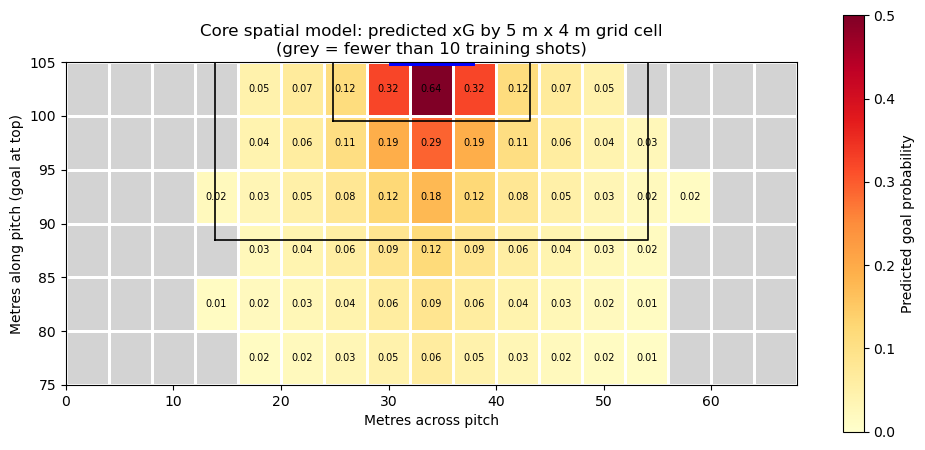

cells: (17, 6) masked: 40 max p: 0.642


In [9]:
GRID_X, GRID_Y = 5, 4          # cell size in metres (along pitch, across pitch)
X_MIN = 75                     # show the attacking end of the pitch only
MIN_SHOTS = 10                 # grey out cells with fewer training shots than this

x_edges = np.arange(X_MIN, PITCH_L + 1e-9, GRID_X)
y_edges = np.arange(0, PITCH_W + 1e-9, GRID_Y)
x_cent = (x_edges[:-1] + x_edges[1:]) / 2
y_cent = (y_edges[:-1] + y_edges[1:]) / 2

# Model features at the centre of every cell
gx, gy = np.meshgrid(x_cent, y_cent)          # rows = y cells, columns = x cells
dgl = PITCH_L - gx
lat = np.abs(gy - PITCH_W / 2)
dy = gy - PITCH_W / 2
a = np.sqrt(dgl ** 2 + (dy - GOAL_W / 2) ** 2)
b = np.sqrt(dgl ** 2 + (dy + GOAL_W / 2) ** 2)
ang = np.arccos(np.clip((a ** 2 + b ** 2 - GOAL_W ** 2) / (2 * a * b), -1, 1))

grid = pd.DataFrame({"const": 1.0, "dist_goal_line": dgl.ravel(),
                     "lateral_offset": lat.ravel(), "angle_to_goal": ang.ravel()})
p_cell = np.asarray(core_fit.predict(grid)).reshape(gx.shape)

# Number of training shots in each cell, to hide cells the model has barely seen
shots_x = train["x"] * PITCH_L / 120
shots_y = train["y"] * PITCH_W / 80
counts, _, _ = np.histogram2d(shots_y, shots_x, bins=[y_edges, x_edges])
p_masked = np.ma.masked_where(counts < MIN_SHOTS, p_cell)

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(figsize=(10, 5.5))

# Vertical pitch: horizontal axis = across the pitch, vertical axis = towards goal (goal at top)
mesh = ax.pcolormesh(y_edges, x_edges, p_masked.T, cmap=cmap, vmin=0, vmax=0.5,
                     edgecolor="white", linewidth=0.8)

# Label each cell with its predicted probability
for i in range(p_cell.shape[0]):          # i indexes y cells
    for j in range(p_cell.shape[1]):      # j indexes x cells
        if counts[i, j] >= MIN_SHOTS:
            ax.text(y_cent[i], x_cent[j], f"{p_cell[i, j]:.2f}",
                    ha="center", va="center", fontsize=7)

# Pitch markings: penalty area, six-yard box, goal
ax.plot([13.85, 54.15, 54.15, 13.85, 13.85], [88.5, 88.5, 105, 105, 88.5], "k-", lw=1.2)
ax.plot([24.85, 43.15, 43.15, 24.85, 24.85], [99.5, 99.5, 105, 105, 99.5], "k-", lw=1.2)
ax.plot([PITCH_W / 2 - GOAL_W / 2, PITCH_W / 2 + GOAL_W / 2], [105, 105], "b-", lw=5)

ax.set_xlim(0, PITCH_W); ax.set_ylim(X_MIN, PITCH_L); ax.set_aspect("equal")
ax.set_xlabel("Metres across pitch")
ax.set_ylabel("Metres along pitch (goal at top)")
ax.set_title(f"Core spatial model: predicted xG by {GRID_X} m x {GRID_Y} m grid cell\n"
             f"(grey = fewer than {MIN_SHOTS} training shots)")
fig.colorbar(mesh, ax=ax, label="Predicted goal probability", shrink=0.8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_core_xg_pitch_map.png", dpi=200)
plt.show()
print("cells:", p_cell.shape, "masked:", int((counts < MIN_SHOTS).sum()),
      "max p:", round(p_cell.max(), 3))

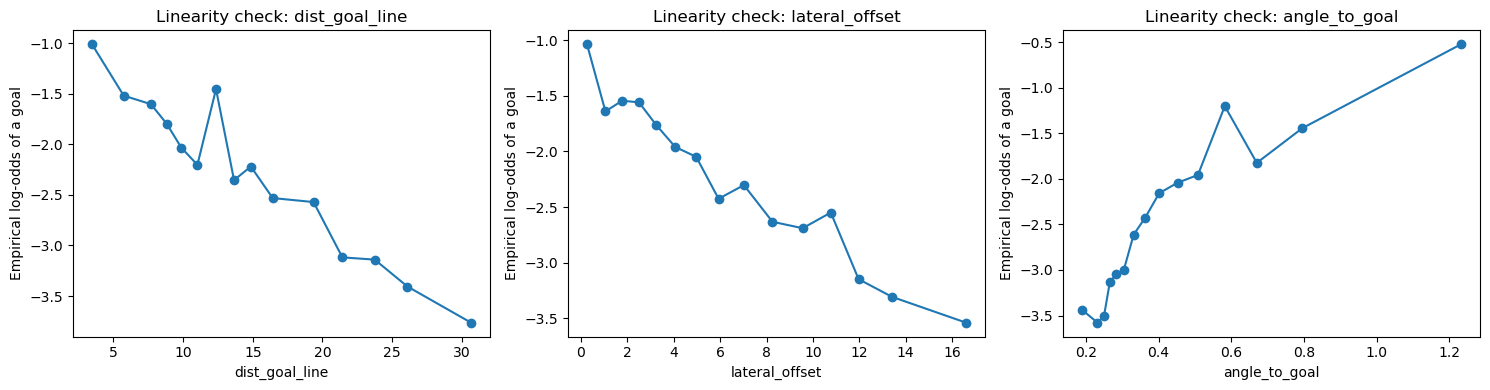

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, CORE_FEATURES):
    bins = pd.qcut(train[feat], 15, duplicates="drop")
    emp = (train.assign(bin=bins)
                .groupby("bin", observed=True)
                .agg(feature=(feat, "mean"), rate=("result", "mean")))
    ax.plot(emp["feature"], np.log(emp["rate"] / (1 - emp["rate"])), "o-")
    ax.set_xlabel(feat)
    ax.set_ylabel("Empirical log-odds of a goal")
    ax.set_title(f"Linearity check: {feat}")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_core_linearity_check.png", dpi=200)
plt.show()

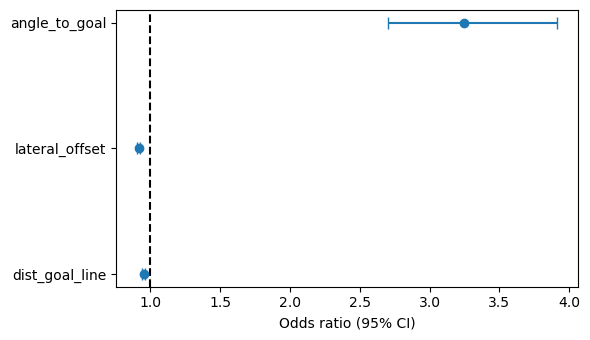

In [11]:
o = or_table.drop("const")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(o["odds_ratio"], range(len(o)),
            xerr=[o["odds_ratio"] - o["ci_low"], o["ci_high"] - o["odds_ratio"]],
            fmt="o", capsize=4)
ax.axvline(1, color="k", ls="--")
ax.set_yticks(range(len(o)))
ax.set_yticklabels(o.index)
ax.set_xlabel("Odds ratio (95% CI)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_core_odds_ratios.png", dpi=200)
plt.show()